# Notebook 18: Discrete Spectra in Γ: a Γ-Level Synthesis

**Goal:** Ask where the discreteness of hydrogen's energy levels shows up in an indivisible stochastic process, whose
only dynamical data are the transition matrices $\Gamma(t\leftarrow 0)$, and how discreteness is tied to indivisibility.

This notebook is a **synthesis, not a discovery.** $\Gamma_{jj}(t)$ is the standard quantum survival probability, so its
Fourier content (Bohr frequencies), its long-time average (the inverse participation ratio) and the link between a nonzero
average and discrete spectrum (Wiener's theorem; RAGE) are textbook results. The indivisibility lemma of section 4 is a
short corollary of the Bocchieri–Loinger recurrence theorem and known contractivity results. The Wallstrom section uses
Smolin's ring and the standard twist–flux (fluxoid) equivalence. What the notebook adds is the assembly in $\Gamma$ language
(see Prior work).

By the end of this notebook you will be able to:
- Read Bohr's frequency condition off $\Gamma$: its entries oscillate at energy *differences* only, and the bound-state
  lines sit at $\tfrac12(1/n^2 - 1/m^2)$ hartree
- See the bound states' share of $\Gamma$'s long-time memory stay fixed as the box grows while the continuum's share falls,
  as Wiener's theorem and RAGE predict
- Prove that a finite unistochastic process with a time-independent law is indivisible at every time at which $\Gamma$ is
  not a permutation, and say exactly what Markov chains can and cannot do
- Watch division events erase the spectral lines
- Restate Wallstrom's objection to Nelson's stochastic mechanics in $\Gamma$ language: a non-quantized circulation is a
  different law (a flux), which $\Gamma$ generically sees, with exact blind spots $\Gamma(\alpha) = \Gamma(N/2-\alpha)$ on bare rings

<!-- sources:papers-1-3 -->
**Sources.** "Paper 1, 2, 3" are Jacob A. Barandes's papers:
- Paper 1: "The Stochastic-Quantum Correspondence", arXiv:2302.10778 (*Philosophy of Physics* 3(1), 8, 2025).
- Paper 2: "The Stochastic-Quantum Theorem", arXiv:2309.03085.
- Paper 3: "Quantum Systems as Indivisible Stochastic Processes", arXiv:2507.21192 (*Stud. Hist. Phil. Sci.* 119, 102213, 2026).

Other works are cited in the text by author and arXiv number or journal reference; the full list is in `REFERENCES.md`.

In [1]:
import sys
import os
sys.path.insert(0, os.path.abspath('..'))

%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
from isp.spectrum import (SpectralModel, radial_hydrogen_hamiltonian, ring_hamiltonian,
                          distinguishability, revival, record_chain, is_permutation)

## 1. Hydrogen as a Process on Radii

The configurations are radii $r_i = ih$ on a grid ($h = 0.1$ bohr) inside a box of radius $R$: "the electron is at radius $r_i$"
(s-waves only, $\ell = 0$). The law is $\Gamma(t\leftarrow 0) = |U(t)|^2$ with $U = e^{-iHt}$ and
$H = -\tfrac12\,d^2/dr^2 - 1/r$ in atomic units. Setting the charge $Z = 0$ removes the attraction and leaves the same box
with no bound states, our "unbound" control.

The grid's bound levels match the Rydberg formula $-1/2n^2$ to about 0.2%; the grid, not the stochastic reading, sets that error.

In [2]:
h = 0.1
H, r = radial_hydrogen_hamiltonian(h, 160.0)
atom = SpectralModel(H)
bound = atom.E < 0
print(f"{atom.n} configurations (radii {r[0]:.1f} to {r[-1]:.1f} bohr), {bound.sum()} bound levels in a box of R = 160")
for n in range(1, 5):
    print(f"  n = {n}: grid E = {atom.E[n-1]:+.5f}   Rydberg -1/2n² = {-0.5/n**2:+.5f}")

G = atom.gamma(3.0)
print(f"\nΓ(3 ← 0): columns sum to 1: {np.allclose(G.sum(0), 1)};  rows too (unistochastic): {np.allclose(G.sum(1), 1)};"
      f"  a permutation: {is_permutation(G)}")

1599 configurations (radii 0.1 to 159.9 bohr), 11 bound levels in a box of R = 160
  n = 1: grid E = -0.49876   Rydberg -1/2n² = -0.50000
  n = 2: grid E = -0.12492   Rydberg -1/2n² = -0.12500
  n = 3: grid E = -0.05554   Rydberg -1/2n² = -0.05556
  n = 4: grid E = -0.03125   Rydberg -1/2n² = -0.03125



Γ(3 ← 0): columns sum to 1: True;  rows too (unistochastic): True;  a permutation: False


## 2. Spectral Lines Are Rhythms in Γ

For real $H$ with eigenpairs $(E_n, v_n)$, every entry of $\Gamma$ is

$$\Gamma_{ij}(t) = \sum_n a_n^2 + \sum_{n<m} 2a_na_m\cos\big((E_n - E_m)t\big), \qquad a_n = v_n(i)\,v_n(j).$$

Only *differences* of energies appear. Absolute energies are invisible to $\Gamma$, and the frequencies it does contain are
exactly Bohr's $\omega = (E_n - E_m)/\hbar$ ($\hbar = 1$, so the frequencies below are energy differences in hartree), a
postulate in 1913, here a property of the transition statistics. (This is the standard
Fourier content of quantum transition probabilities, read in $\Gamma$.)

We start the electron at $r = 1$ bohr and list the strongest bound–bound lines of its return probability $\Gamma_{jj}(t)$.

Strongest bound-bound lines in Γ_jj(t), start r = 1 bohr:
  1 ↔ 2:  frequency 0.37383   Rydberg ½(1/n² − 1/m²) = 0.37500   amplitude 4.99e-04
  1 ↔ 3:  frequency 0.44322   Rydberg ½(1/n² − 1/m²) = 0.44444   amplitude 1.37e-04
  1 ↔ 4:  frequency 0.46751   Rydberg ½(1/n² − 1/m²) = 0.46875   amplitude 5.63e-05
  1 ↔ 5:  frequency 0.47876   Rydberg ½(1/n² − 1/m²) = 0.48000   amplitude 2.85e-05
  1 ↔ 6:  frequency 0.48487   Rydberg ½(1/n² − 1/m²) = 0.48611   amplitude 1.64e-05
  2 ↔ 3:  frequency 0.06938   Rydberg ½(1/n² − 1/m²) = 0.06944   amplitude 1.17e-05

Share of total oscillation amplitude in bound-bound lines: 0.08%


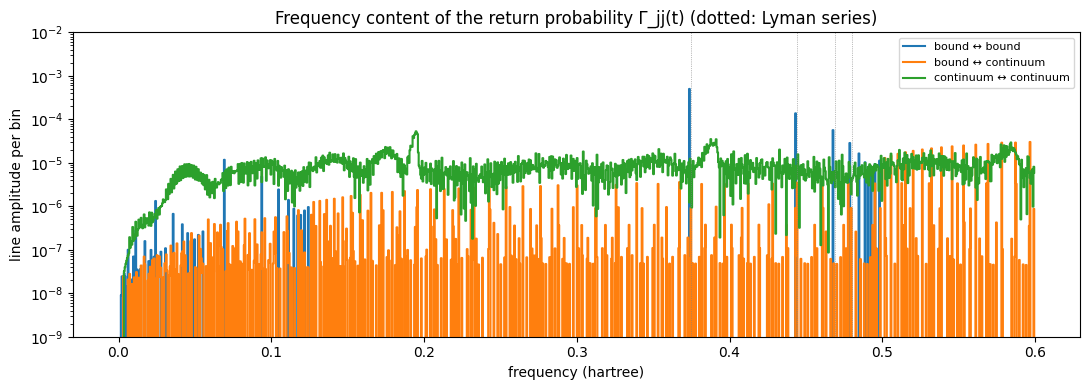

In [3]:
j = int(round(1.0 / h)) - 1          # configuration r = 1 bohr
freq, amp, c0 = atom.lines(j, j)
nn, mm = np.triu_indices(atom.n, 1)
bb = bound[nn] & bound[mm]

print("Strongest bound-bound lines in Γ_jj(t), start r = 1 bohr:")
for k in np.argsort(-np.where(bb, amp, 0))[:6]:
    n1, n2 = nn[k] + 1, mm[k] + 1
    print(f"  {n1} ↔ {n2}:  frequency {freq[k]:.5f}   Rydberg ½(1/n² − 1/m²) = {0.5*(1/n1**2 - 1/n2**2):.5f}"
          f"   amplitude {amp[k]:.2e}")
print(f"\nShare of total oscillation amplitude in bound-bound lines: {amp[bb].sum() / amp.sum():.2%}")

fig, ax = plt.subplots(figsize=(11, 4))
edges = np.linspace(0, 0.6, 1201)
kind = [('bound ↔ bound', bb), ('bound ↔ continuum', bound[nn] ^ bound[mm]), ('continuum ↔ continuum', ~bound[nn] & ~bound[mm])]
for label, sel in kind:
    hist, _ = np.histogram(freq[sel], bins=edges, weights=amp[sel])
    ax.semilogy(edges[:-1], hist + 1e-12, drawstyle='steps-post', label=label)
for n2 in range(2, 6):
    ax.axvline(0.5 * (1 - 1 / n2**2), color='gray', lw=0.5, ls=':')
ax.set_ylim(1e-9, 1e-2); ax.set_xlabel('frequency (hartree)'); ax.set_ylabel('line amplitude per bin')
ax.set_title('Frequency content of the return probability Γ_jj(t) (dotted: Lyman series)'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

The bound–bound lines are a small fraction of the total amplitude from a point start (a grid point is mostly high-energy
continuum), but they are sharp lines, while everything involving the continuum is a smear. Section 3 shows which part survives
when the box is made larger.

## 3. Discrete Spectrum as Persistent Return Probability (Wiener/RAGE)

Two quantities measure how much the process remembers where it started, at arbitrarily late times:

- the long-time average of the return probability, $\overline{\Gamma_{jj}} = \sum_n |v_n(j)|^4$ for a nondegenerate spectrum
  (the inverse participation ratio of the start $j$);
- the long-time variance of $\Gamma_{jj}(t)$, the size of oscillations that never die out: $\sum_{n\neq m} |v_n(j)|^4|v_m(j)|^4$
  when all gaps are distinct. The code groups pairs that share a gap, which matters for the $Z = 0$ box, whose symmetric
  spectrum has many coinciding gaps.

Each splits into a bound part and parts involving the continuum. In a finite box everything is discrete, so the test is how each
part scales with $R$.

    R   bound avg   continuum avg   Z=0 avg   |  bound-bound var   total var   Z=0 var
    40   0.00294     0.00353       0.00375   |   1.395e-07       3.330e-05   2.792e-05
    80   0.00294     0.00177       0.00188   |   1.366e-07       1.364e-05   7.006e-06


   160   0.00294     0.00088       0.00094   |   1.364e-07       6.115e-06   1.755e-06


   320   0.00294     0.00044       0.00047   |   1.363e-07       2.932e-06   4.394e-07

log-log slopes vs R: continuum avg -0.999,  Z=0 avg -1.000,  total var -1.167,  Z=0 var -1.997


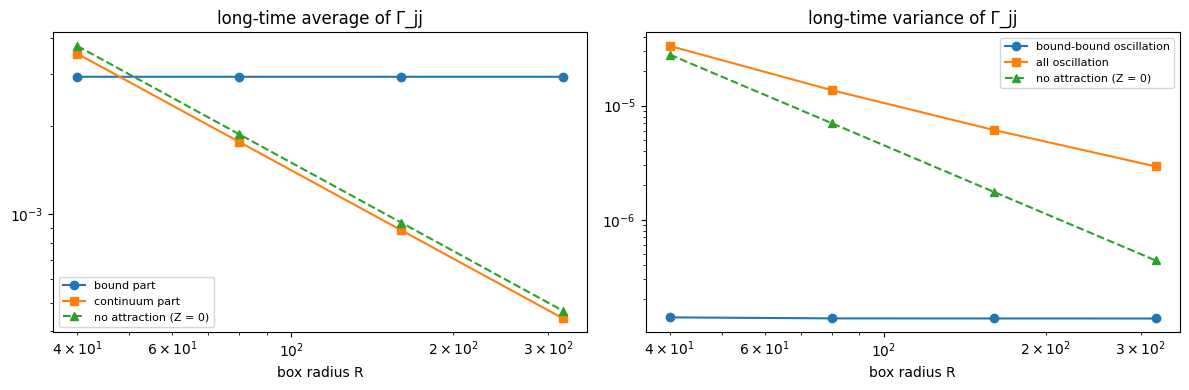

In [4]:
print("    R   bound avg   continuum avg   Z=0 avg   |  bound-bound var   total var   Z=0 var")
rows = []
for R in [40.0, 80.0, 160.0, 320.0]:
    m = SpectralModel(radial_hydrogen_hamiltonian(h, R)[0]); b = m.E < 0
    f = SpectralModel(radial_hydrogen_hamiltonian(h, R, Z=0.0)[0])
    row = (R, m.time_average(j, j, b), m.time_average(j, j, ~b), f.time_average(j, j),
           m.time_variance(j, j, b), m.time_variance(j, j), f.time_variance(j, j))
    rows.append(row)
    print(f"  {R:4.0f}   {row[1]:.5f}     {row[2]:.5f}       {row[3]:.5f}   |   {row[4]:.3e}       {row[5]:.3e}   {row[6]:.3e}")
rows = np.array(rows)
slope = lambda col: np.polyfit(np.log(rows[:, 0]), np.log(rows[:, col]), 1)[0]
print(f"\nlog-log slopes vs R: continuum avg {slope(2):.3f},  Z=0 avg {slope(3):.3f},  total var {slope(5):.3f},  Z=0 var {slope(6):.3f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].loglog(rows[:, 0], rows[:, 1], 'o-', label='bound part')
ax[0].loglog(rows[:, 0], rows[:, 2], 's-', label='continuum part')
ax[0].loglog(rows[:, 0], rows[:, 3], '^--', label='no attraction (Z = 0)')
ax[0].set_xlabel('box radius R'); ax[0].set_title('long-time average of Γ_jj'); ax[0].legend(fontsize=8)
ax[1].loglog(rows[:, 0], rows[:, 4], 'o-', label='bound-bound oscillation')
ax[1].loglog(rows[:, 0], rows[:, 5], 's-', label='all oscillation')
ax[1].loglog(rows[:, 0], rows[:, 6], '^--', label='no attraction (Z = 0)')
ax[1].set_xlabel('box radius R'); ax[1].set_title('long-time variance of Γ_jj'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

The bound contributions barely change with $R$ (the average is the same to the printed 5 decimals, the variance changes by about 2% from
$R = 40$ to 320). The continuum's share of the average falls as $1/R$, its share of the variance
falls faster, approaching $1/R$ only for large boxes, and with no attraction everything falls. As $R\to\infty$ the only memory
left is the bound states'. This is consistent with the RAGE theorem (Ruelle; Amrein–Georgescu; Enss), which is an
infinite-volume statement that the box sequence illustrates but does not prove. In $\Gamma$ language, the Wiener/RAGE
characterization of point spectrum reads:

> **On an infinite configuration space, $\Gamma_{jj}$ has a nonzero long-time average exactly when the start $j$ overlaps the
> discrete (pure-point) spectrum (Wiener's theorem). With two or more such levels it also oscillates forever at their Bohr
> frequencies.**

Measured by the long-time variance, the oscillation statement is an "exactly when" too: $\Gamma_{jj}$ keeps oscillating
exactly when the start overlaps two or more distinct discrete levels. A single bound level gives a nonzero average with no
lasting oscillation, and continuous components (singular-continuous ones included) drop out of every long-time average, so they
add nothing to the variance. (Pointwise, a singular-continuous component can keep $\Gamma_{jj}$ from decaying, but not in
these averages.) Which values the levels take is not decided by any of this. Those
come from the law (here $-1/r$), as in standard quantum theory.

## 4. Why the Process Cannot Be Divisible

**Contractivity.** If a process is divisible from $t'$ to $t$, then $\Gamma(t) = \Gamma(t\leftarrow t')\Gamma(t')$ with a
stochastic middle factor, and stochastic matrices never increase the Kolmogorov distance between two columns. So the
distinguishability $D_{jk}(t) = \tfrac12\sum_i |\Gamma_{ij}(t) - \Gamma_{ik}(t)|$ of two starting points can never rise again.
Any revival $\max_{t>t'}\,[D(t) - D(t')] > 0$ (notebook 06's $R$) proves indivisibility.

**Recurrence.** With finitely many configurations and a time-independent $H$, $U(t)$ is almost periodic (the Bocchieri–Loinger
quantum recurrence theorem): for every $\varepsilon$ there are arbitrarily late times at which every phase $e^{-iE_n t}$ is within
$\varepsilon$ of a common value, so $\Gamma(t)$ comes back as close as we like to the identity and every $D_{jk}$ back to 1. If
$\Gamma(t')$ is not a permutation, some row has two nonzero entries, two columns overlap, and $D_{jk}(t') < 1$ for that pair.
Hence:

> **For a finite unistochastic process generated by a time-independent Hamiltonian, the process is indivisible at every time
> $t'$ at which $\Gamma(t')$ is not a permutation**: some later $\Gamma(t\leftarrow t')$ cannot be stochastic.

Both conditions matter. If $\Gamma$ returns exactly to a permutation (for $H = \sigma_x$, $\Gamma(\pi) = I$), the process is
divisible *at that time*. If the law changes in time (for example, is switched off), recurrence fails and the process can be
divisible from then on. The same argument covers any pure-point spectrum, where recurrence still holds; it says nothing about
hydrogen's continuum. Discreteness is sufficient, not necessary: notebook 03's free Gaussian (continuous spectrum) is
indivisible too.

The ingredients are published: quantum recurrence (Bocchieri and Loinger 1957), no revival under divisible dynamics
(Buscemi–Datta, arXiv:1408.7062; Doukas, arXiv:2602.22095, Prop. 1; classically Smirne, Stabile and Vacchini), and the two-level
Rabi case (Gillespie 1994; Pimenta, arXiv:2505.08785; Doukas §4.2.2). That closed finite systems are non-Markovian is also argued
by Glick and Adami (Found. Phys. 50, 1008 (2020)). We have not seen the corollary above stated explicitly.

**What Markov chains can and cannot do.** A time-homogeneous continuous-time Markov chain has $\Gamma(t) = e^{tQ}$ with rates
$Q_{ij}\ge 0$ ($i\ne j$) and columns summing to 0. Gershgorin's theorem puts every eigenvalue of $Q$ in a disk centred at
$Q_{jj}\le 0$ of radius $|Q_{jj}|$, which touches the imaginary axis only at 0, so it cannot oscillate *undamped*. It can
oscillate with damping (a one-way cycle, below), and a time-dependent divisible chain can oscillate forever. What no divisible
process can do is revive $D$.

Atom, starts r = 1 and r = 3 bohr: revival R = 0.138 over 0 ≤ t ≤ 400
   within [0, 100): revival 0.138
   within [100, 200): revival 0.085
   within [200, 300): revival 0.080
   within [300, 400): revival 0.071

Random 4-configuration law: D falls to 0.723, then returns to 0.999997 at t = 77.71 (recurrence)
σ_x law: Γ(0.3) a permutation: False;  Γ(π) a permutation: True  (divisible at t' = π)

Random 6-state rate matrix: largest real part among nonzero eigenvalues = -1.930 (< 0: every mode decays)
One-way 20-cycle Markov chain: Γ_00 falls to 0.0005, rises again to 0.0889 at t = 20.0 (above 1/N = 0.05): a damped oscillation


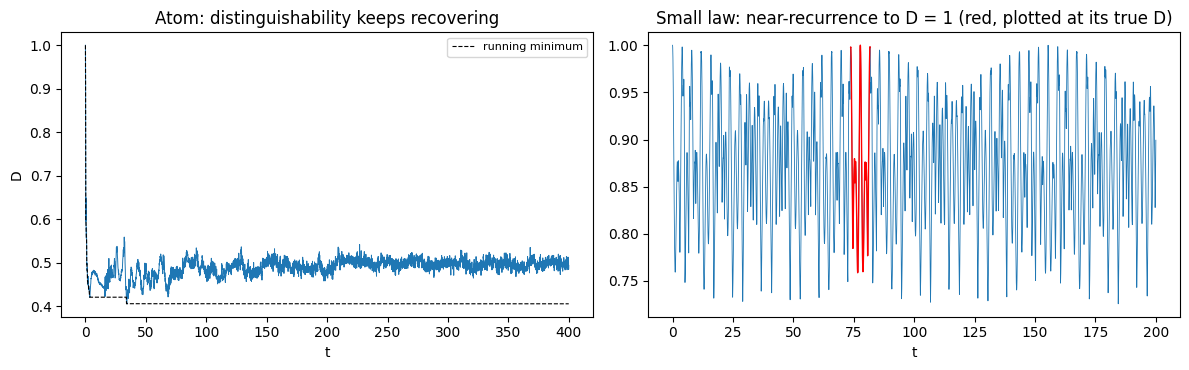

In [5]:
ts = np.linspace(0, 400, 4001)
D = distinguishability(atom.columns(9, ts), atom.columns(29, ts))
print(f"Atom, starts r = 1 and r = 3 bohr: revival R = {revival(D):.3f} over 0 ≤ t ≤ 400")
for T0 in [0, 100, 200, 300]:
    s = (ts >= T0) & (ts < T0 + 100)
    print(f"   within [{T0}, {T0 + 100}): revival {revival(D[s]):.3f}")

small = SpectralModel((lambda A: A + A.T)(np.random.default_rng(7).normal(size=(4, 4))))
tl = np.linspace(0, 3000, 300001)
Ds = distinguishability(small.columns(0, tl), small.columns(1, tl))
k = np.argmax(np.where(tl > 5, Ds, 0))
print(f"\nRandom 4-configuration law: D falls to {Ds.min():.3f}, then returns to {Ds[k]:.6f} at t = {tl[k]:.2f} (recurrence)")

sx = SpectralModel(np.array([[0.0, 1.0], [1.0, 0.0]]))
print(f"σ_x law: Γ(0.3) a permutation: {is_permutation(sx.gamma(0.3))};  Γ(π) a permutation: {is_permutation(sx.gamma(np.pi))}"
      f"  (divisible at t' = π)")

rng = np.random.default_rng(3)
Q = rng.random((6, 6)); np.fill_diagonal(Q, 0); Q -= np.diag(Q.sum(0))
ev = np.linalg.eigvals(Q)
print(f"\nRandom 6-state rate matrix: largest real part among nonzero eigenvalues = {np.sort(ev.real)[-2]:.3f} (< 0: every mode decays)")

Nc = 20
Qc = np.zeros((Nc, Nc))
for i in range(Nc):
    Qc[(i + 1) % Nc, i] = 1.0; Qc[i, i] = -1.0
tc = np.linspace(0, 60, 6001)
g00 = np.array([expm(Qc * t)[0, 0] for t in tc])
kc = np.argmax(np.where(tc > 10, g00, 0))
print(f"One-way 20-cycle Markov chain: Γ_00 falls to {g00[(tc > 5) & (tc < tc[kc])].min():.4f}, rises again to {g00[kc]:.4f}"
      f" at t = {tc[kc]:.1f} (above 1/N = {1/Nc:.2f}): a damped oscillation")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(ts, D, lw=0.7); ax[0].plot(ts, np.minimum.accumulate(D), 'k--', lw=0.8, label='running minimum')
ax[0].set_xlabel('t'); ax[0].set_ylabel('D'); ax[0].set_title('Atom: distinguishability keeps recovering'); ax[0].legend(fontsize=8)
ax[1].plot(tl[:20000], Ds[:20000], lw=0.6); ax[1].plot(tl[k-400:k+400], Ds[k-400:k+400], 'r', lw=1)
ax[1].set_xlabel('t'); ax[1].set_title('Small law: near-recurrence to D = 1 (red, plotted at its true D)')
plt.tight_layout(); plt.show()

## 5. Division Events Erase the Lines

A division event every $\tau$ turns the process into Barandes's Markov chain $\Gamma(\tau)^n$ (Paper 1, eq. 57; notebook 11).
$\Gamma(\tau)$ is doubly stochastic, and here its second-largest eigenvalue modulus is below 1, so the chain relaxes toward the
uniform distribution $1/N$. (Double stochasticity alone is not enough: a swap matrix never relaxes.) The time-averaged memory of
section 3 and the oscillations at the Bohr frequencies are gone, and $D$ can only fall.

uniform 1/N = 0.00063


τ = 0.5: |λ₂| = 0.9976;  return probability at t = 600: 0.00069;  revival of D along the chain: 0.0e+00


τ = 2.0: |λ₂| = 0.9618;  return probability at t = 600: 0.00063;  revival of D along the chain: 0.0e+00


τ = 5.0: |λ₂| = 0.7729;  return probability at t = 600: 0.00063;  revival of D along the chain: 1.1e-18


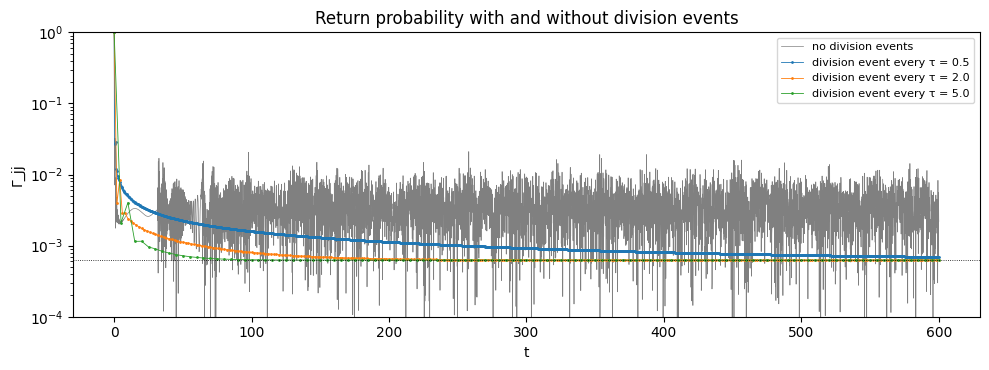

In [6]:
print(f"uniform 1/N = {1 / atom.n:.5f}")
fig, ax = plt.subplots(figsize=(10, 3.8))
tt = np.linspace(0, 600, 6001)
ax.plot(tt, atom.entry(j, j, tt), lw=0.5, color='gray', label='no division events')
for tau in [0.5, 2.0, 5.0]:
    G = atom.gamma(tau)
    lam2 = np.sort(np.abs(np.linalg.eigvals(G)))[-2]
    ns = np.arange(0, int(600 / tau) + 1)
    P = np.empty(len(ns)); M = np.eye(atom.n)[:, j]
    Dn = np.empty(len(ns)); Mk = np.eye(atom.n)[:, 29]
    for i_, n in enumerate(ns):
        P[i_] = M[j]; Dn[i_] = 0.5 * np.abs(M - Mk).sum()
        M = G @ M; Mk = G @ Mk
    ax.plot(ns * tau, P, '.-', ms=2, lw=0.6, label=f'division event every τ = {tau}')
    print(f"τ = {tau}: |λ₂| = {lam2:.4f};  return probability at t = 600: {P[-1]:.5f};  revival of D along the chain: {revival(Dn):.1e}")
ax.set_yscale('log'); ax.set_ylim(1e-4, 1); ax.set_xlabel('t'); ax.set_ylabel('Γ_jj')
ax.axhline(1 / atom.n, color='k', lw=0.6, ls=':'); ax.legend(fontsize=8); ax.set_title('Return probability with and without division events')
plt.tight_layout(); plt.show()

With $\tau = 0.5$ the chain is still about 10% above $1/N$ at $t = 600$ ($|\lambda_2|$ is close to 1); larger $\tau$ relaxes faster.

## 6. Wallstrom's Objection, Read in Γ

Nelson's stochastic mechanics rebuilds quantum theory from a Markov diffusion with density $\rho$ and velocity field $v$
(the Madelung variables). Wallstrom (1994) showed that those equations also admit solutions whose circulation
$\oint v\,dl$ is not a multiple of $2\pi$, wavefunctions that are not single-valued, so quantization of angular momentum has
to be added by hand.

The simplest setting is a ring, which is also Smolin's test case for the objection (quant-ph/0609109 §IV). A wavefunction that
picks up a phase $e^{2\pi i\alpha}$ around the ring is the same as a single-valued one for a ring threaded by a flux
$2\pi\alpha$. This is the standard twist–flux (fluxoid) equivalence, read in the Madelung setting as a holonomy by Foskett and
Tronci (arXiv:2003.08664); see also notebook 15. The twisted ring's energies (hopping $J = 1$) are $-2\cos(2\pi(m+\alpha)/N)$, are still discrete, but shifted. In ISP
the configurations are the sites, the law is $\Gamma$, and the twist is part of the law. The question becomes: does $\Gamma$
see $\alpha$?

In [7]:
def max_diff(Ha, Hb, ts=np.linspace(0.05, 10, 400)):
    a, b = SpectralModel(Ha), SpectralModel(Hb)
    return max(np.abs(a.gamma(t) - b.gamma(t)).max() for t in ts)

print("max over t of |Γ(α) − Γ(0)|, bare ring:")
for N in [7, 8]:
    for alpha in [0.25, 0.5]:
        print(f"  N = {N}, α = {alpha}: {max_diff(ring_hamiltonian(N, 0), ring_hamiltonian(N, alpha)):.3f}")
print(f"  N = 7, α = 1.25 vs α = 0.25: {max_diff(ring_hamiltonian(7, 1.25), ring_hamiltonian(7, 0.25)):.1e}  (only α mod 1 matters)")

print("\nthe blind spot Γ(α) = Γ(N/2 − α) on bare rings:")
for N, a, b, what in [(7, 0.1, 0.4, "odd: α vs ½ − α"), (7, 0.5, 0.0, "odd: half twist vs none"),
                      (8, 0.2, -0.2, "even: α vs −α"), (8, 0.2, 0.3, "even: α vs ½ − α (not a blind spot)")]:
    print(f"  N = {N}, α = {a} vs {b}  [{what}]: {max_diff(ring_hamiltonian(N, a), ring_hamiltonian(N, b)):.1e}")

print("\nodd ring N = 7, α = ½ vs 0, with a site potential V:")
rngV = np.random.default_rng(5)
for label, Vd in [("constant V = 0.4", 0.4 * np.ones(7)),
                  ("structured V", 0.7 * np.cos(4 * np.pi * np.arange(7) / 7) + 0.3 * (np.arange(7) % 2)),
                  ("random V, size 1e-3", 1e-3 * rngV.normal(size=7))]:
    V = np.diag(Vd)
    print(f"  {label:22s}: {max_diff(ring_hamiltonian(7, 0) + V, ring_hamiltonian(7, 0.5) + V):.1e}")

max over t of |Γ(α) − Γ(0)|, bare ring:
  N = 7, α = 0.25: 0.788
  N = 7, α = 0.5: 0.000
  N = 8, α = 0.25: 0.927
  N = 8, α = 0.5: 0.929
  N = 7, α = 1.25 vs α = 0.25: 3.2e-15  (only α mod 1 matters)

the blind spot Γ(α) = Γ(N/2 − α) on bare rings:
  N = 7, α = 0.1 vs 0.4  [odd: α vs ½ − α]: 7.7e-15
  N = 7, α = 0.5 vs 0.0  [odd: half twist vs none]: 3.1e-15
  N = 8, α = 0.2 vs -0.2  [even: α vs −α]: 4.1e-15
  N = 8, α = 0.2 vs 0.3  [even: α vs ½ − α (not a blind spot)]: 3.3e-01

odd ring N = 7, α = ½ vs 0, with a site potential V:
  constant V = 0.4      : 6.4e-15
  structured V          : 8.6e-01
  random V, size 1e-3   : 3.1e-03


- **Generic case.** $\Gamma$ changes with the twist (by up to 0.79–0.93 here), and depends on it only modulo 1. A non-quantized
  circulation is not an extra solution of the same law. It is a different law, and the transition statistics tell the two apart.
  Wallstrom's freedom has no counterpart in ISP's initial data either: a process starts at a division event from a probability
  distribution, which carries no velocity field.
- **Blind spots on bare rings.** $-H(\alpha)^*$ is gauge-equivalent to $H(N/2-\alpha)$, and $\Gamma(H) = \Gamma(-H^*)$ (notebook 12),
  so $\Gamma(\alpha) = \Gamma(N/2 - \alpha)$ exactly. Odd rings cannot tell $\alpha$ from $\tfrac12 - \alpha$, so a half-integer twist
  (a double-valued, "spin-½-like" wavefunction) looks like none. Even rings cannot tell $\alpha$ from $-\alpha$: they cannot see which way the circulation runs.
- **Breaking the tie.** A constant potential changes nothing. A non-constant site potential generically breaks the tie, by an
  amount that grows with the potential.

Why Wallstrom's extra solutions have no ISP counterpart: Nelson's law depends on the state (the drift is built from $\rho$ and the phase), so it can admit
extra stationary states. $\Gamma$ is one linear map applied to every initial distribution, so the twist must be chosen once, in
the law. Barandes says Nelson-type approaches "all assumed Markovian dynamical laws", which "limited" them (Paper 3 §1, p. 3),
and does not discuss Wallstrom. The closest passages interpolate a permutation process: Barandes, arXiv:2608.04354, §4 (eq. 58) writes
$U(t) = \Sigma^{t}$, and Paper 2 §4.3 (fn. 12, p. 20) builds $\Sigma^{t/\delta t}$ from the eigenphases $\theta_m$ of $\Sigma$, with
energies $E_m = -\hbar\theta_m/\delta t$. Since each $\theta_m$ is fixed only modulo $2\pi$, those energies carry a branch choice.
That remark is ours; Barandes does not make it.

This relocates Wallstrom's condition rather than deriving it: ISP says the twist is a property of the law, visible in $\Gamma$
except at the blind spots above, but not why hydrogen's law carries none. That is as empirical in ISP as the $-1/r$ potential
itself.

## Summary

- **Bohr's frequency rule is built into Γ.** $\Gamma_{ij}(t)$ contains only the frequencies $E_n - E_m$. On the radial
  hydrogen grid the bound–bound lines of the return probability sit at $\tfrac12(1/n^2 - 1/m^2)$ to within about 0.3% (the grid).
- **Discrete spectrum as persistent return probability.** The long-time average and the long-time oscillation of $\Gamma_{jj}$
  have a bound-state part that barely changes with the box (average $2.94\times10^{-3}$ in every box; variance $1.363$–$1.395\times10^{-7}$,
  a 2% change, from 40 to 320 bohr)
  and a continuum part that falls as $1/R$ (the variance approaching it); without the attraction everything falls. This
  illustrates Wiener's theorem and RAGE in $\Gamma$ language.
- **Recurrence forces indivisibility.** For a finite unistochastic process with a time-independent law, the process is
  indivisible at every time at which $\Gamma$ is not a permutation (Bocchieri–Loinger recurrence plus contractivity); the same
  holds for pure-point spectra. Finite time-homogeneous continuous-time Markov chains cannot oscillate undamped (Gershgorin);
  discrete-time chains such as a permutation can. No divisible process can revive distinguishability. The converse fails: continuous spectra can be indivisible too.
- **Division events erase the lines.** With records every τ (and here $|\lambda_2| < 1$) the process relaxes toward uniform and distinguishability never
  revives.
- **Wallstrom in Γ.** A non-quantized circulation is a twisted law, which Γ generically distinguishes (modulo 1), except at the
  exact blind spots $\Gamma(\alpha) = \Gamma(N/2-\alpha)$ of bare rings. ISP relocates the quantization condition into the law; it
  does not derive it.
- **What ISP does not supply:** the values $-1/2n^2$. Those come from the law, as in standard quantum theory.

**Prior work.**
- *Spectral reading:* Bohr frequencies as the Fourier content of transition probabilities, the survival probability and the
  inverse participation ratio $\sum_n|v_n(j)|^4$ are standard. Nonzero time average iff point spectrum is Wiener's theorem; the RAGE
  theorem is Ruelle (Nuovo Cimento A 61, 655 (1969)), Amrein–Georgescu (1973) and Enss (1978).
- *Indivisibility:* quantum recurrence is Bocchieri and Loinger, Phys. Rev. 107, 337 (1957). Contractivity of the Kolmogorov
  distance and revival as a memory witness are Smirne, Stabile and Vacchini (arXiv:1211.5913) and Breuer, Laine and Piilo,
  Phys. Rev. Lett. 103, 210401 (2009); no revival under divisible dynamics is Buscemi–Datta (arXiv:1408.7062) and Doukas
  (arXiv:2602.22095, Prop. 1); two-level cases are Gillespie, Phys. Rev. A 49, 1607 (1994) and Pimenta (arXiv:2505.08785); closed
  systems as non-Markovian, Glick and Adami (2020). Barandes notes that $\Gamma(t)\Gamma^{-1}(t')$ is not generically stochastic
  (Paper 1 §3.5, eqs. 37–38); the section 4 corollary sharpens this for time-independent laws. The Markov chain
  $\Gamma(\tau)^n$ is Paper 1, eq. 57.
- *Wallstrom:* Phys. Rev. A 49, 1613 (1994). Responses that add an assumption: Schmelzer (arXiv:1101.5774), Derakhshani
  (arXiv:1510.06391). Responses that dispute the premise: Smolin (quant-ph/0609109, whose §IV is the ring), Fritsche–Haugk
  (arXiv:0912.3442), Kuipers (arXiv:2301.05467, the condition "is part of the theory"). Geometric recastings: Reddiger–Poirier
  (J. Phys. A 56, 193001 (2023)), Foskett–Tronci (arXiv:2003.08664). $\Gamma(H) = \Gamma(-H^*)$ is notebook 12, derived from Paper 3
  §4.1.

Barandes's papers do not discuss Wallstrom or bound-state spectra; the only spectral passages are Paper 2 §4.3 fn. 12 and
arXiv:2608.04354 §4. We have not seen the section 4 corollary or the ring blind spots stated in ISP form. See
`notes/lit-quantization-wallstrom-2026-11-15.md` for the literature checks behind this notebook.